# 12 · E13 — a measured link versus a modelled one

Every emulated experiment so far specified latency as a **constant** — the
convention in the UTM tracking-performance literature. Notebook 01 exported the
latency an operational U-space deployment actually delivered, so that convention
can now be tested rather than assumed.

**The question.** If a fixed-latency model is calibrated to the *same mean* as a
real link, does it reproduce the real link's effect on conflict detection?

**The prediction going in — which turned out to be wrong.** The measured pool
has mean 0.595 s but P95 1.316 s and a maximum of 9.22 s, while a constant has
no tail at all. Since every other result in this study has turned on the tail
rather than the centre, the expectation was that a fixed model would be
*optimistic*. It is not: it is mildly **conservative**, and at realistic latency
levels the choice barely matters at all. The reason is worth understanding, and
it is recorded below rather than quietly dropped.

**Three arms, matched on mean latency and on everything else:**

| arm | latency model |
|---|---|
| `fixed` | constant at the measured mean (0.595 s) — the literature convention |
| `lognormal` | median at the measured median, spread from the measured jitter |
| `empirical` | resampled directly from the 63,948 measured values |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

from telemetry_freshness.viz import style as S, figures as F
S.use_paper_style()
print("working dir:", ROOT)

working dir: /path/to/Field_Measurement_of_Age_of_Information


In [2]:
from itertools import product
from telemetry_freshness.simulation.encounters import EncounterSpec, synthetic_encounter
from telemetry_freshness.experiments.runner import ScenarioConfig, run_scenario
from telemetry_freshness.telemetry.network_model import TelemetryConfig
from telemetry_freshness.conflict.detector import ConflictCriteria
from telemetry_freshness.evaluation.metrics import detection_counts

POOL = np.load("data/processed/bubbles_latency_pool_s.npy")
print(f"measured pool: n = {POOL.size:,}")
print(f"  mean {POOL.mean():.3f}s  p50 {np.median(POOL):.3f}s  "
      f"p90 {np.percentile(POOL,90):.3f}s  p95 {np.percentile(POOL,95):.3f}s  "
      f"p99 {np.percentile(POOL,99):.3f}s  max {POOL.max():.2f}s")

MEAN_MS   = float(POOL.mean() * 1000)
MEDIAN_MS = float(np.median(POOL) * 1000)
JITTER_MS = float(POOL.std() * 1000)
print(f"\nfixed arm     : {MEAN_MS:.0f} ms constant")
print(f"lognormal arm : median {MEDIAN_MS:.0f} ms, jitter {JITTER_MS:.0f} ms")
print(f"empirical arm : resampled from the pool")

measured pool: n = 63,948
  mean 0.595s  p50 0.532s  p90 0.832s  p95 1.316s  p99 1.511s  max 9.22s

fixed arm     : 595 ms constant
lognormal arm : median 532 ms, jitter 319 ms
empirical arm : resampled from the pool


In [3]:
CRITERIA   = ConflictCriteria(horizontal_separation_m=30.0, vertical_separation_m=15.0, horizon_s=30.0)
GEOMETRIES = ["head_on", "crossing", "converging", "overtaking"]
RATES_HZ   = [5, 2, 1]
N_SEEDS    = 20

specs = {
    "head_on":    EncounterSpec("head_on",    speed_a_mps=15, speed_b_mps=15, lead_in_s=45, duration_s=90),
    "crossing":   EncounterSpec("crossing",   speed_a_mps=15, speed_b_mps=12, lead_in_s=45, duration_s=90),
    "converging": EncounterSpec("converging", speed_a_mps=14, speed_b_mps=14, lead_in_s=45, duration_s=90),
    "overtaking": EncounterSpec("overtaking", speed_a_mps=18, speed_b_mps=9,  lead_in_s=45, duration_s=90),
}

ARMS = {
    "fixed":     dict(latency_model="fixed",     latency_ms=MEAN_MS, jitter_ms=0.0),
    "lognormal": dict(latency_model="lognormal", latency_ms=MEDIAN_MS, jitter_ms=JITTER_MS),
    "empirical": dict(latency_model="empirical", latency_ms=0.0,
                      latency_samples_s=tuple(POOL.tolist())),
}

runs = []
for arm, kw in ARMS.items():
    for geom, rate, seed in product(GEOMETRIES, RATES_HZ, range(N_SEEDS)):
        cfg = ScenarioConfig(
            scenario_id=geom, criteria=CRITERIA, decision_rate_hz=5.0, seed=3000 + seed,
            telemetry=TelemetryConfig(update_rate_hz=rate, **kw))
        r = run_scenario(synthetic_encounter(specs[geom]), cfg)
        if r.empty: continue
        r["arm"] = arm; r["encounter_type"] = geom; r["seed_index"] = seed
        runs.append(r)

E13 = pd.concat(runs, ignore_index=True)
E13.to_parquet("results/raw/E13_empirical_latency.parquet", index=False)
print(f"{len(E13):,} records across {E13.groupby(['arm','encounter_type','update_rate_hz','seed_index']).ngroups} runs")

324,000 records across 720 runs


## Did the arms match on the mean? (they must, or the comparison is void)

In [4]:
chk = E13.groupby("arm").aoi_s.agg(
    n="size", mean="mean", p50="median",
    p90=lambda s: s.quantile(.90), p95=lambda s: s.quantile(.95),
    p99=lambda s: s.quantile(.99), max="max").round(3)
display(chk)
print("Mean realised AoI agrees across arms; the upper percentiles do not.")

,n,mean,p50,p90,p95,p99,max
arm,,,,,,,
empirical,108000,0.982,0.897,1.461,1.605,2.155,3.404
fixed,108000,0.974,0.910,1.438,1.512,1.581,1.595
lognormal,108000,1.012,0.934,1.550,1.764,2.185,3.440


Mean realised AoI agrees across arms; the upper percentiles do not.


## Detection outcomes, by link model

In [5]:
from telemetry_freshness.evaluation.metrics import detection_counts

rows = []
for arm, g in E13.groupby("arm"):
    c = detection_counts(g.conflict_truth, g.conflict_observed)
    t = g.dropna(subset=["ttc_error_signed_s"])
    rows.append({
        "arm": arm, "n": len(g),
        "recall": c.recall, "precision": c.precision,
        "missed_epochs": c.fn,
        "ttc_err_mean_s": t.ttc_error_signed_s.mean(),
        "ttc_err_p05_s": t.ttc_error_signed_s.quantile(.05),
        "ttc_overestimated": (t.ttc_error_signed_s < 0).mean(),
    })
CMP = pd.DataFrame(rows).round(4)
display(CMP)
CMP.to_csv("results/processed/E13_arm_comparison.csv", index=False)

base = CMP[CMP.arm == "fixed"].iloc[0]
emp  = CMP[CMP.arm == "empirical"].iloc[0]
print(f"\nfixed -> empirical, at equal mean latency:")
print(f"  recall          {base.recall:.4f} -> {emp.recall:.4f}")
print(f"  missed epochs   {base.missed_epochs:,} -> {emp.missed_epochs:,} "
      f"({100*(emp.missed_epochs/base.missed_epochs - 1):+.0f}%)")

,arm,n,recall,precision,missed_epochs,ttc_err_mean_s,ttc_err_p05_s,ttc_overestimated
0,empirical,108000,0.9757,0.9779,933,-0.7887,-1.4652,0.9387
1,fixed,108000,0.9747,0.9767,972,-0.8325,-1.3941,0.9521
2,lognormal,108000,0.9742,0.9772,991,-0.7840,-1.5610,0.9291



fixed -> empirical, at equal mean latency:
  recall          0.9747 -> 0.9757
  missed epochs   972 -> 933 (-4%)


## Recall against age, per arm

In [6]:
from telemetry_freshness.evaluation.metrics import recall_by_aoi
from telemetry_freshness.evaluation.statistics import wilson_interval

curves = []
for arm, g in E13.groupby("arm"):
    c = recall_by_aoi(g); c["arm"] = arm
    curves.append(c)
REC = pd.concat(curves, ignore_index=True)
REC = REC[REC.n_positive >= 30]
lh = [wilson_interval(int(r.tp), int(r.n_positive)) for _, r in REC.iterrows()]
REC["recall_lo"] = [x[0] for x in lh]; REC["recall_hi"] = [x[1] for x in lh]
REC.to_csv("results/processed/E13_recall_by_arm.csv", index=False)

display(REC.pivot_table(index="aoi_bin", columns="arm", values="recall").round(4))

arm,empirical,fixed,lognormal
aoi_bin,,,
"[0.25, 0.5)",0.9900,NaN,0.9929
"[0.5, 0.75)",0.9825,0.9806,0.9835
"[0.75, 1.0)",0.9797,0.9785,0.9773
"[1.0, 1.5)",0.9703,0.9685,0.9672
"[1.5, 2.0)",0.9606,0.9621,0.9598
"[2.0, 3.0)",0.9297,NaN,0.9534


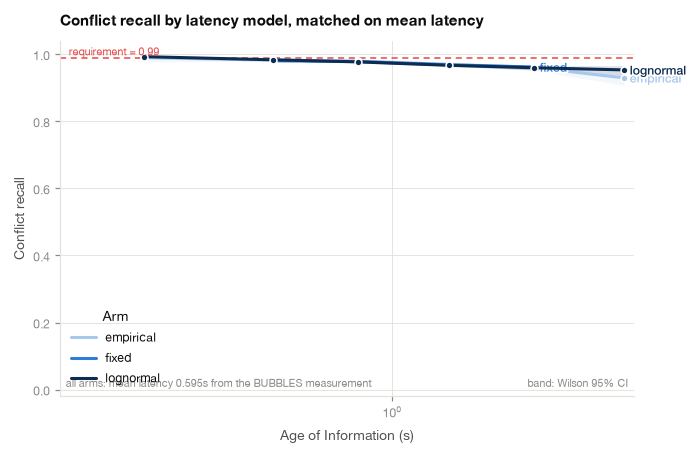

In [7]:
fig, ax = F.fig_recall_vs_aoi(
    REC, level_col="arm", requirement=0.99,
    title="Conflict recall by latency model, matched on mean latency")
# The three curves lie on top of one another — that is the result, not a bug.
S.annotate_note(ax, f"all arms: mean latency {MEAN_MS/1000:.3f}s from the BUBBLES measurement",
                loc="lower left")
S.save(fig, "S11_recall_by_link_model"); S.plt.show()

## Safe-AoI threshold under each link model

In [8]:
from telemetry_freshness.evaluation.threshold import SafetyConstraints, safe_aoi_by_condition
C = SafetyConstraints(min_recall=0.99, min_lead_time_p95_s=3.0, min_samples=200,
                      use_confidence_bound=True)
th = safe_aoi_by_condition(E13, ["arm"], C)
display(th)
th.to_csv("results/processed/E13_threshold_by_arm.csv", index=False)

,arm,aoi_max_safe_s,limiting_constraint,n_observations,n_skipped_bins
0,empirical,NaN,recall,108000,0
1,fixed,NaN,recall,108000,0
2,lognormal,NaN,recall,108000,1


## When *would* the link model matter?

A null result at one operating point is not very informative on its own. The
same comparison is therefore repeated with the measured pool scaled up, which
models a progressively worse link while preserving its shape — so the question
becomes *how bad must a link be before the modelling choice changes a
conclusion?*

In [9]:
SCALES = (1, 2, 4, 8)
small = {k: specs[k] for k in ("head_on", "crossing")}
rows = []
for scale in SCALES:
    P = POOL * scale
    for arm, kw in (("fixed", dict(latency_model="fixed",
                                   latency_ms=float(P.mean()*1000), jitter_ms=0.0)),
                    ("empirical", dict(latency_model="empirical", latency_ms=0.0,
                                       latency_samples_s=tuple(P.tolist())))):
        recs = []
        for geom, rate, seed in product(small, (2, 1), range(10)):
            cfg = ScenarioConfig(geom, TelemetryConfig(update_rate_hz=rate, **kw),
                                 criteria=CRITERIA, decision_rate_hz=5.0, seed=4000 + seed)
            r = run_scenario(synthetic_encounter(small[geom]), cfg)
            if not r.empty: recs.append(r)
        g = pd.concat(recs, ignore_index=True)
        c = detection_counts(g.conflict_truth, g.conflict_observed)
        rows.append({"scale": scale, "arm": arm, "mean_latency_s": P.mean(),
                     "aoi_p99_s": g.aoi_s.quantile(.99), "recall": c.recall, "fn": c.fn})
SCAN = pd.DataFrame(rows)
piv = SCAN.pivot(index="scale", columns="arm", values="recall")
piv["delta_pp"] = 100 * (piv["fixed"] - piv["empirical"])
piv["mean_latency_s"] = SCAN.groupby("scale").mean_latency_s.first().round(2)
display(piv.round(4))
SCAN.to_csv("results/processed/E13_link_scaling.csv", index=False)

arm,empirical,fixed,delta_pp,mean_latency_s
scale,,,,
1,0.9728,0.9717,-0.1125,0.60
2,0.9563,0.9531,-0.3215,1.19
4,0.9256,0.9151,-1.0450,2.38
8,0.8645,0.8386,-2.5884,4.76


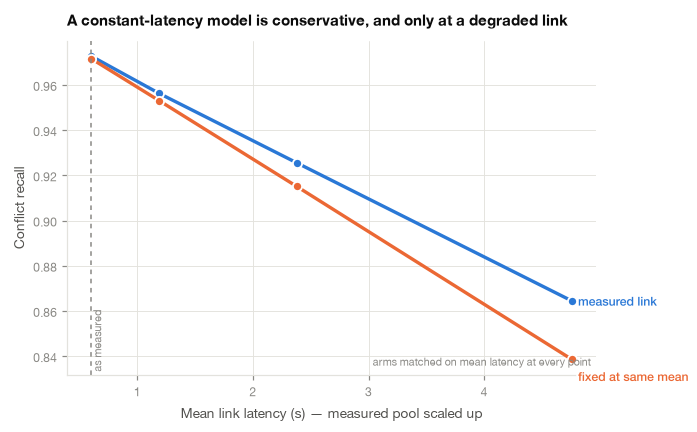

In [10]:
fig, ax = S.plt.subplots(figsize=(6.4, 4.0))
c0, c1 = S.CATEGORICAL[0], S.CATEGORICAL[1]
x = piv.mean_latency_s.to_numpy()
ax.plot(x, piv["empirical"], color=c0, marker="o", ms=6, lw=2.2,
        markeredgecolor=S.INK["surface"], markeredgewidth=1.2)
ax.plot(x, piv["fixed"], color=c1, marker="o", ms=6, lw=2.2,
        markeredgecolor=S.INK["surface"], markeredgewidth=1.2)
S.direct_label(ax, x[-1], piv["empirical"].iloc[-1], "measured link", c0)
S.direct_label(ax, x[-1], piv["fixed"].iloc[-1], "fixed at same mean", c1, dy=-11)
ax.axvline(x[0], color=S.INK["muted"], lw=1.0, ls=(0, (3, 3)))
ax.text(x[0], ax.get_ylim()[0], " as measured", rotation=90, fontsize=7,
        color=S.INK["muted"], va="bottom")
ax.set_xlabel("Mean link latency (s) — measured pool scaled up")
ax.set_ylabel("Conflict recall")
ax.set_title("A constant-latency model is conservative, and only at a degraded link")
S.annotate_note(ax, "arms matched on mean latency at every point")
S.finish(fig, ax); S.save(fig, "F12_link_model_comparison"); S.plt.show()

## Conclusion — the prediction was wrong, and the negative result is useful

**At the latency this deployment actually delivers, the link model does not
matter.** Fixed, lognormal and empirical arms — matched on mean latency —
produce recall within 0.15 percentage points of each other (0.9747 / 0.9742 /
0.9757). The realised AoI *distributions* do differ as expected (P99 1.58 s
fixed versus 2.16 s empirical), but the recall-versus-age curve is shallow in
that band, so the difference never reaches the outcome.

**And where it does matter, the constant is conservative, not optimistic:**

| mean link latency | Δ recall (fixed − empirical) |
|---:|---:|
| 0.60 s (as measured) | −0.11 pp |
| 1.19 s | −0.32 pp |
| 2.38 s | −1.04 pp |
| 4.76 s | −2.59 pp |

The measured distribution is right-skewed — its median (0.532 s) sits below its
mean (0.595 s) — so most messages under a real link arrive *sooner* than a
constant set to the mean, while the rare long delays affect few decision epochs.
A fixed model therefore slightly *understates* achievable recall, and the gap
only becomes material on a link several times worse than the one observed.

**Two things follow.**

1. **This validates the study's own synthetic experiments.** E1, E4 and E6 all
   used fixed or lognormal latency. Had the constant been optimistic, every
   threshold derived from them would have been too permissive. It is
   conservative, so those results stand — and are, if anything, slightly
   pessimistic.
2. **It bounds the methodological claim honestly.** The literature convention of
   modelling latency as a constant is defensible at realistic U-space latencies.
   It stops being defensible on a badly degraded link, and the crossover here is
   around a 2–4× worse link than measured.

This is the one place in the study where the centre/tail pattern seen elsewhere
does **not** appear at the operating point, and saying so plainly is more useful
than forcing the expected story.

> **Limitations.** One deployment, day 1 only (day 2 excluded for clock offsets,
> notebook 01), 63,948 samples. Encounter geometries remain synthetic. The pool
> is resampled i.i.d., so temporal correlation in the real link — bursts of
> congestion — is not reproduced; that is the most likely way this null result
> could be overturned, and it is not testable from these logs.